# Classification — Social_Network_Ads.csv

Goal: predict whether a user purchased (`Purchased` = 0/1) after seeing a
social network ad, using Age and EstimatedSalary. Compare several
classification algorithms and record the best one.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

RESULTS_PATH = Path("../results/results_summary.csv")
DATASET_NAME = "Social_Network_Ads.csv"
TASK = "Classification"
RANDOM_STATE = 42

## 1. Load & explore

In [2]:
df = pd.read_csv("../Social_Network_Ads.csv")
print(df.shape)
df.head()

(400, 5)


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [4]:
df["Purchased"].value_counts(normalize=True)

Purchased
0    0.6425
1    0.3575
Name: proportion, dtype: float64

## 2. Preprocessing
Features: Gender (encoded), Age, EstimatedSalary. User ID is an identifier,
not a predictive feature, so it is dropped. Features are scaled since
several algorithms here (KNN, SVM, Logistic Regression) are scale-sensitive.

In [5]:
data = df.copy()
le = LabelEncoder()
data["Gender"] = le.fit_transform(data["Gender"])  # Male/Female -> 1/0

feature_cols = ["Gender", "Age", "EstimatedSalary"]
X = data[feature_cols]
y = data["Purchased"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Train multiple classification algorithms

In [6]:
models = {
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "NaiveBayes": GaussianNB(),
}

runs = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    auc = roc_auc_score(y_test, proba)
    runs[name] = {"model": model, "accuracy": acc, "f1": f1, "roc_auc": auc, "preds": preds}
    print(f"{name:20s} accuracy={acc:.4f}  f1={f1:.4f}  roc_auc={auc:.4f}")

LogisticRegression   accuracy=0.8100  f1=0.6984  roc_auc=0.9106
KNN                  accuracy=0.9100  f1=0.8767  roc_auc=0.9180
SVM (RBF)            accuracy=0.9000  f1=0.8649  roc_auc=0.9549
DecisionTree         accuracy=0.8800  f1=0.8378  roc_auc=0.8759


RandomForest         accuracy=0.9000  f1=0.8649  roc_auc=0.9238
NaiveBayes           accuracy=0.8700  f1=0.8116  roc_auc=0.9475


/home/ayush/ML-assignment-2/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 4. Pick the best model (by ROC-AUC — robust to the dataset's modest class
imbalance) and inspect its confusion matrix

Best algorithm: SVM (RBF) (roc_auc=0.9549)


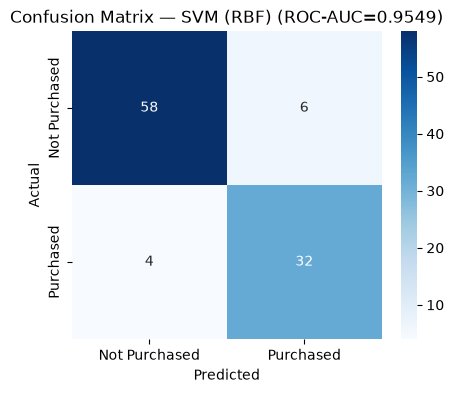

In [7]:
best_name = max(runs, key=lambda n: runs[n]["roc_auc"])
best_run = runs[best_name]
print(f"Best algorithm: {best_name} (roc_auc={best_run['roc_auc']:.4f})")

cm = confusion_matrix(y_test, best_run["preds"])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Purchased", "Purchased"],
            yticklabels=["Not Purchased", "Purchased"])
plt.title(f"Confusion Matrix — {best_name} (ROC-AUC={best_run['roc_auc']:.4f})")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.savefig("../results/classification_best_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Record results

In [8]:
rows = [
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": name, "Metric": "ROC_AUC",
     "Score": round(r["roc_auc"], 4),
     "Params": f"accuracy={r['accuracy']:.4f}, f1={r['f1']:.4f}"}
    for name, r in runs.items()
]
results_df = pd.DataFrame(rows)
results_df["Best"] = results_df["Algorithm"] == best_name
print(results_df.to_string(index=False))

               Dataset           Task          Algorithm  Metric  Score                     Params  Best
Social_Network_Ads.csv Classification LogisticRegression ROC_AUC 0.9106 accuracy=0.8100, f1=0.6984 False
Social_Network_Ads.csv Classification                KNN ROC_AUC 0.9180 accuracy=0.9100, f1=0.8767 False
Social_Network_Ads.csv Classification          SVM (RBF) ROC_AUC 0.9549 accuracy=0.9000, f1=0.8649  True
Social_Network_Ads.csv Classification       DecisionTree ROC_AUC 0.8759 accuracy=0.8800, f1=0.8378 False
Social_Network_Ads.csv Classification       RandomForest ROC_AUC 0.9238 accuracy=0.9000, f1=0.8649 False
Social_Network_Ads.csv Classification         NaiveBayes ROC_AUC 0.9475 accuracy=0.8700, f1=0.8116 False


In [9]:
RESULTS_PATH.parent.mkdir(exist_ok=True)
if RESULTS_PATH.exists():
    existing = pd.read_csv(RESULTS_PATH)
    existing = existing[existing["Dataset"] != DATASET_NAME]
    combined = pd.concat([existing, results_df], ignore_index=True)
else:
    combined = results_df
combined.to_csv(RESULTS_PATH, index=False)
print(f"Saved to {RESULTS_PATH.resolve()}")

Saved to /home/ayush/ML-assignment-2/results/results_summary.csv
